# Part C · Part-to-whole legality, and the pie-ranking experiment

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 4

Before drawing any share, slide 32 asks three questions. Are the parts **exclusive**? Is the whole
**meaningful**? Is the share **actually the question**? Then the Week 2 channel ranking (position > length >
angle > area) gets tested on a real reader.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import clear_output, display

import tslib
from vizlib import PALETTE, save_fig, style_defaults

DATA = Path("data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]

## 1 · The three conditions, tested in code

### (a) The four `touch_*` columns of `case08_channel_attrib.csv`

In [2]:
c8 = pd.read_csv(DATA / "case08_channel_attrib.csv")
flags = [c for c in c8.columns if c.startswith("touch_")]
ex = tslib.exclusivity_check(c8, flags)
print(f"exclusive: {ex['exclusive']}   shares sum to {ex['sum_pct']}%   "
      f"customers in 2+ parts: {ex['n_multi']} ({ex['pct_multi']}%)   in none: {ex['n_zero']}")

exclusive: False   shares sum to 130.98%   customers in 2+ parts: 1105 (27.62%)   in none: 0


- **Exclusive?** No. 1,105 customers sit in two or more parts.
- **Meaningful whole?** No. The parts add up to 131% of the customers, so the "whole" doesn't exist.
- **Share the question?** The question is *reach* ("how many customers did search touch?"), which is a
  rate per channel, not a slice of one whole.

**Verdict: no pie, no stacked bar. A bar chart is fine** (one bar per channel, % of customers reached), as
long as it says the bars overlap and don't sum to 100%. That's the redesign in Part A case 8.

### (b) The eight rows of `shares_eight.csv`

In [3]:
shares = pd.read_csv(DATA / "shares_eight.csv")
cat = pd.read_csv(DATA / "revenue_catalogue.csv")
parents = cat.groupby("subcategory").category.nunique()
print(shares.to_string(index=False))
print(f"\nsum of shares: {shares.share_pct.sum():.6f}")
assert abs(shares.share_pct.sum() - 100) < 1e-6
print(f"each sub-category has exactly one parent category: {(parents == 1).all()}; "
      f"sub-categories in the catalogue: {cat.subcategory.nunique()}")

slice subcategory  share_pct
    A      Phones       24.6
    B     Laptops       18.4
    C       Audio       15.0
    D   Wearables        9.2
    E     Cameras        6.1
    F      Drones        2.4
    G    Footwear       11.2
    H Accessories       13.1

sum of shares: 100.000000
each sub-category has exactly one parent category: True; sub-categories in the catalogue: 8


- **Exclusive?** Yes. Each sub-category is a separate group of SKUs with exactly one parent (one SKU is
  duplicated across two sub-categories in the raw catalogue. Part D removes the copy, and these shares
  match the cleaned version).
- **Meaningful whole?** Yes. The catalogue has exactly eight sub-categories, so these eight *are* the
  whole of net revenue, and they sum to exactly 100.
- **Share the question?** Yes: "what fraction of revenue does each line bring in?"

**Verdict: a pie is legal. A bar chart is better.** All three tests pass, but there are eight slices and
three of them (C 15.0%, H 13.1%, G 11.2%) are within four points of each other. Angle can't separate
those reliably, and length can. Questions 2 and 3 test that claim.

### (c) Premium vs other revenue in `case09_premium_share.csv`, 2025Q4

In [4]:
c9 = pd.read_csv(DATA / "case09_premium_share.csv").set_index("quarter")
q4 = c9.loc["2025Q4"]
parts = pd.Series({"premium": q4.premium_revenue_pkr_m, "other": q4.total_revenue_pkr_m - q4.premium_revenue_pkr_m})
print(parts, f"\nsum {parts.sum()} = total {q4.total_revenue_pkr_m}")
assert abs(parts.sum() - q4.total_revenue_pkr_m) < 1e-9
print(f"\ntotal revenue 2024Q1 -> 2025Q4: {c9.total_revenue_pkr_m.iloc[0]:.0f} -> {q4.total_revenue_pkr_m:.0f}")

premium    228.0
other      372.0
dtype: float64 
sum 600.0 = total 600.0

total revenue 2024Q1 -> 2025Q4: 1000 -> 600


- **Exclusive?** Yes. "Other" is defined as total minus premium, so every rupee is in exactly one part.
- **Meaningful whole?** Yes. It's that quarter's total revenue.
- **Share the question?** **No.** The claim, "a record", is about *change over time*, and over that time
  the whole fell from 1,000 to 600. A share of a whole that is itself shrinking 40% hides the main fact.

**Verdict for this claim: neither.** A two-slice pie of 2025Q4 alone would be perfectly legal (two parts
is a pie's best case), but it answers "how is this quarter split?", and nobody asked that. The question
needs absolute revenue over time, drawn as lines or bars from zero (Part A case 9).

## 2 · The ranking experiment

Two stimuli, saved as PNGs. The pie follows the brief exactly: the file's order, `startangle=90`,
`counterclock=False`, **no numbers**. The bars use the same letters, sorted, also with no numbers.

'charts\\stimulus_bars.png'

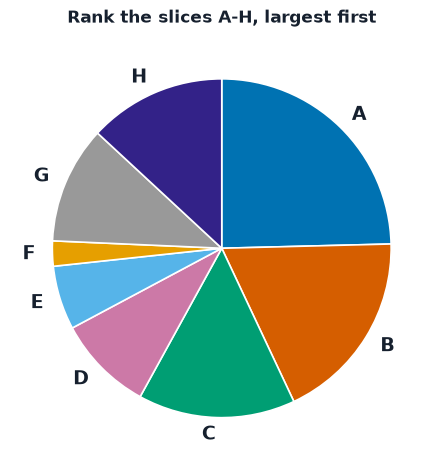

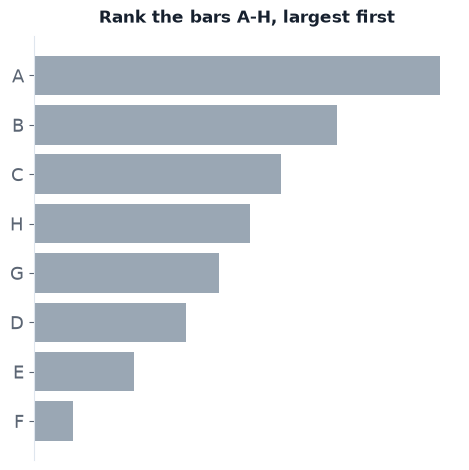

In [5]:
COLOURS = [PALETTE["series"][0], PALETTE["series"][1], PALETTE["series"][2], PALETTE["series_4th"],
           "#56B4E9", "#E69F00", "#999999", "#332288"]


def draw_pie(ax):
    ax.pie(shares.share_pct, labels=shares.slice, colors=COLOURS, startangle=90, counterclock=False,
           wedgeprops=dict(edgecolor="white", linewidth=1.2), textprops=dict(fontsize=14, fontweight="bold"))
    ax.set_title("Rank the slices A-H, largest first", loc="center")


def draw_bars(ax):
    s = shares.sort_values("share_pct")
    ax.barh(s.slice, s.share_pct, color=GREY)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="y", labelsize=13)
    ax.set_title("Rank the bars A-H, largest first", loc="center")


fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_pie(ax)
save_fig(fig, CHARTS / "stimulus_pie.png")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_bars(ax)
save_fig(fig, CHARTS / "stimulus_bars.png")

### Running it

The reader sees the **pie first**, then the bars, so the bars can't teach them the answer for the pie.
Each stimulus is timed with `time.perf_counter()` from the moment it's shown to the moment they press
Enter on their answer.

1. Set `READER` and `RUN_EXPERIMENT = True`, and run this cell with the reader at the screen.
2. They type the eight letters, largest first (e.g. `ABCHGDEF`).
3. Set `RUN_EXPERIMENT = False`, then **Restart & Run All**.

In [6]:
RESULTS = Path("pie_ranking_results.csv")
RUN_EXPERIMENT = False
READER = "a classmate"


def ask(draw, stimulus, reader):
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    draw(ax)
    display(fig)
    plt.close(fig)
    start = time.perf_counter()
    order = input("Type the letters A-H, largest first, then press Enter: ").strip().upper().replace(" ", "")
    return {"reader": reader, "stimulus": stimulus, "order": order,
            "seconds": round(time.perf_counter() - start, 1)}


if RUN_EXPERIMENT:
    input("You'll see a chart. Rank its parts from largest to smallest. Press Enter when ready.")
    rows = [ask(draw_pie, "pie", READER), ask(draw_bars, "bars", READER)]
    clear_output()
    pd.DataFrame(rows).to_csv(RESULTS, mode="a", header=not RESULTS.exists(), index=False)

if RESULTS.exists():
    results = pd.read_csv(RESULTS)
    display(results)
else:
    results = None
    print("No pie_ranking_results.csv yet. Set RUN_EXPERIMENT = True and run this cell with your reader.")

No pie_ranking_results.csv yet. Set RUN_EXPERIMENT = True and run this cell with your reader.


## 3 · Score it

In [7]:
TRUE = "".join(shares.sort_values("share_pct", ascending=False).slice)
print("true order:", TRUE, " (", ", ".join(f"{r.slice} {r.share_pct}" for r in
                                         shares.sort_values("share_pct", ascending=False).itertuples()), ")")


def score(order):
    wrong = [i + 1 for i, (got, want) in enumerate(zip(order, TRUE)) if got != want]
    return pd.Series({"letters_misplaced": len(wrong),
                      "wrong_ranks": ", ".join(map(str, wrong)) or "none",
                      "top_two_right": order[:2] == TRUE[:2],
                      "bottom_one_right": order[-1:] == TRUE[-1:]})


if results is None:
    print("Waiting for pie_ranking_results.csv. Run step 2 first.")
else:
    bad = results[results.order.str.len() != 8]
    if len(bad):
        print(f"{len(bad)} answer(s) are not 8 letters long, check them:", bad.order.tolist())
    display(pd.concat([results, results.order.apply(score)], axis=1))

true order: ABCHGDEF  ( A 24.6, B 18.4, C 15.0, H 13.1, G 11.2, D 9.2, E 6.1, F 2.4 )
Waiting for pie_ranking_results.csv. Run step 2 first.


The deck predicts that a reader gets the **top two (A, B) and the bottom one (F) right** on the pie, and
mixes up the middle, where **C (15.0%), H (13.1%) and G (11.2%)** are three points apart, so the errors
should fall at ranks 3-5. On sorted bars, ranking should be close to free: the answer is the reading order.

> **My reader's result** *(fill in from the table)*: who took it; pie: __ letters misplaced, at ranks __,
> in __ s; bars: __ misplaced, in __ s. Did the errors fall where the deck predicted (ranks 3-5)? If not,
> where, and why might that be?

**What one reader can and can't support.** One reader, one try at each stimulus. That can show that a pie
*can* be misread, and roughly how much slower it is for this person. It can't estimate how often people
in general get it wrong, and the order effect (pie always first) means the bars benefit from a reader who
has already studied the shares. It's a demonstration, not an experiment.

## 4 · My rule

> *(One sentence, in my own words: when will I draw a pie from now on?)*